In [43]:

import torch
import torchvision
import pandas as pd
import numpy as np
import sklearn

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("STEP 1 COMPLETED SUCCESSFULLY")




PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Pandas: 2.2.3
Scikit-learn: 1.6.1
GPU available: True
GPU: Tesla T4
STEP 1 COMPLETED SUCCESSFULLY


In [44]:

import importlib.util

if importlib.util.find_spec("datasets") is None:
    %pip install -q "datasets>=3.0,<4.0"
else:
    print("Hugging Face datasets already installed")

print("STEP 2A COMPLETED")


Hugging Face datasets already installed
STEP 2A COMPLETED


In [45]:

from datasets import load_dataset

print("Dataset library imported successfully")
print("STEP 2B COMPLETED")


Dataset library imported successfully
STEP 2B COMPLETED


In [46]:

from datasets import load_dataset

print("Loading Amazon Berkeley Objects dataset...")

listings = load_dataset(
    "hyper3labs/amazon-berkeley-objects",
    "listings",
    split="train"
)

print("Dataset loaded successfully!")
print("Number of records:", len(listings))
print("Available columns:", listings.column_names)

print("STEP 3 COMPLETED")


Loading Amazon Berkeley Objects dataset...
Dataset loaded successfully!
Number of records: 147702
Available columns: ['item_id', 'country', 'marketplace', 'domain_name', 'title', 'brand', 'color', 'style', 'product_type', 'product_type_readable', 'node_paths', 'department', 'hierarchy_path', 'main_image_id', 'main_image_path', 'main_image_url', 'raw_listing_json']
STEP 3 COMPLETED


In [47]:

import pandas as pd

df = listings.to_pandas()

print("Total records:", len(df))

print("\nMissing values:")
print(df[
    ["item_id", "title", "product_type_readable",
     "main_image_url"]
].isnull().sum())

print("\nDuplicate product IDs:")
print(df["item_id"].duplicated().sum())

print("\nTop 15 product categories:")
print(
    df["product_type_readable"]
    .value_counts()
    .head(15)
)

usable = df.dropna(
    subset=[
        "item_id",
        "title",
        "product_type_readable",
        "main_image_url"
    ]
)

print("\nUsable records:", len(usable))
print("STEP 4 COMPLETED")


Total records: 147702

Missing values:
item_id                    0
title                      0
product_type_readable      0
main_image_url           575
dtype: int64

Duplicate product IDs:
2087

Top 15 product categories:
product_type_readable
cellular phone case           64853
shoes                         12965
grocery                        6546
home                           5264
home bed and bath              3082
home furniture and decor       2255
chair                          2100
boot                           2009
sandal                         1845
finering                       1540
health personal care           1449
finenecklacebraceletanklet     1377
accessory                      1362
sofa                           1199
office products                1152
Name: count, dtype: int64

Usable records: 147127
STEP 4 COMPLETED


In [48]:

clean_df = df.dropna(
    subset=[
        "item_id",
        "title",
        "product_type_readable",
        "main_image_url"
    ]
).copy()

for col in [
    "item_id",
    "title",
    "product_type_readable",
    "main_image_url"
]:
    clean_df[col] = clean_df[col].astype(str).str.strip()
    clean_df = clean_df[clean_df[col] != ""]

conflicts = (
    clean_df.groupby("item_id")["product_type_readable"]
    .nunique()
)

print(
    "Product IDs with conflicting categories:",
    (conflicts > 1).sum()
)

clean_df = clean_df.drop_duplicates(
    subset="item_id",
    keep="first"
).reset_index(drop=True)

print("\nRecords after cleaning:", len(clean_df))
print(
    "Unique product IDs:",
    clean_df["item_id"].nunique()
)

print("\nTop 20 categories after cleaning:")
print(
    clean_df["product_type_readable"]
    .value_counts()
    .head(20)
)

print("\nSTEP 5 COMPLETED")


Product IDs with conflicting categories: 89

Records after cleaning: 145050
Unique product IDs: 145050

Top 20 categories after cleaning:
product_type_readable
cellular phone case           64817
shoes                         12188
grocery                        6452
home                           5167
home bed and bath              2944
home furniture and decor       2168
chair                          2099
boot                           1805
sandal                         1674
health personal care           1400
finering                       1390
finenecklacebraceletanklet     1333
accessory                      1282
sofa                           1198
office products                1138
fineearring                    1092
pet supplies                   1058
table                           936
sporting goods                  893
hardware handle                 853
Name: count, dtype: int64

STEP 5 COMPLETED


In [49]:

label_counts = (
    df.dropna(subset=["item_id", "product_type_readable"])
    .groupby("item_id")["product_type_readable"]
    .nunique()
)

conflicting_ids = set(
    label_counts[label_counts > 1].index
)

final_clean_df = clean_df[
    ~clean_df["item_id"].isin(conflicting_ids)
].copy().reset_index(drop=True)

print("Conflicting IDs excluded:", len(conflicting_ids))
print("Remaining records:", len(final_clean_df))

print("\nAvailable product categories:")
print(
    final_clean_df["product_type_readable"]
    .value_counts()
    .head(30)
    .to_string()
)

print("\nSTEP 6 COMPLETED")


Conflicting IDs excluded: 89
Remaining records: 144961

Available product categories:
product_type_readable
cellular phone case           64816
shoes                         12179
grocery                        6438
home                           5160
home bed and bath              2942
home furniture and decor       2167
chair                          2099
boot                           1803
sandal                         1670
health personal care           1400
finering                       1390
finenecklacebraceletanklet     1333
accessory                      1282
sofa                           1198
office products                1136
fineearring                    1092
pet supplies                   1058
table                           935
sporting goods                  892
hardware handle                 853
rug                             817
handbag                         768
light bulb                      753
kitchen                         697
earring                     

In [50]:

category_counts = (
    final_clean_df["product_type_readable"]
    .value_counts()
)

print("Categories with at least 80 products:")
print(category_counts[category_counts >= 80].to_string())

print("\nNumber of eligible categories:",
      (category_counts >= 80).sum())

print("\nSTEP 7 COMPLETED")


Categories with at least 80 products:
product_type_readable
cellular phone case                 64816
shoes                               12179
grocery                              6438
home                                 5160
home bed and bath                    2942
home furniture and decor             2167
chair                                2099
boot                                 1803
sandal                               1670
health personal care                 1400
finering                             1390
finenecklacebraceletanklet           1333
accessory                            1282
sofa                                 1198
office products                      1136
fineearring                          1092
pet supplies                         1058
table                                 935
sporting goods                        892
hardware handle                       853
rug                                   817
handbag                               768
light bulb      

In [51]:

candidate_categories = [
    "cellular phone case",
    "shoes",
    "grocery",
    "home",
    "home bed and bath",
    "home furniture and decor",
    "chair",
    "boot"
]

print("Candidate category counts:\n")

for category in candidate_categories:
    count = (
        final_clean_df["product_type_readable"]
        == category
    ).sum()

    print(f"{category}: {count:,}")

print("\nTotal candidate categories:",
      len(candidate_categories))

print("\nSTEP 8 COMPLETED")


Candidate category counts:

cellular phone case: 64,816
shoes: 12,179
grocery: 6,438
home: 5,160
home bed and bath: 2,942
home furniture and decor: 2,167
chair: 2,099
boot: 1,803

Total candidate categories: 8

STEP 8 COMPLETED


In [52]:

import requests
from PIL import Image
from io import BytesIO

test_df = (
    final_clean_df[
        final_clean_df["product_type_readable"]
        .isin(candidate_categories)
    ]
    .groupby("product_type_readable", group_keys=False)
    .sample(n=3, random_state=42)
)

successful = 0
failed = 0

for _, row in test_df.iterrows():
    try:
        response = requests.get(
            row["main_image_url"],
            timeout=10
        )
        response.raise_for_status()

        image = Image.open(
            BytesIO(response.content)
        )
        image.verify()

        successful += 1

    except Exception as e:
        failed += 1
        print(
            "Failed:",
            row["item_id"],
            str(e)[:100]
        )

print("\nImages tested:", len(test_df))
print("Successful:", successful)
print("Failed:", failed)
print("STEP 9 COMPLETED")



Images tested: 24
Successful: 24
Failed: 0
STEP 9 COMPLETED


In [53]:

from sklearn.model_selection import train_test_split

SEED = 42
SAMPLES_PER_CLASS = 200

selected_df = final_clean_df[
    final_clean_df["product_type_readable"].isin(
        candidate_categories
    )
].copy()

balanced_df = (
    selected_df
    .groupby("product_type_readable", group_keys=False)
    .sample(
        n=SAMPLES_PER_CLASS,
        random_state=SEED
    )
    .reset_index(drop=True)
)

train_df, temp_df = train_test_split(
    balanced_df,
    test_size=0.30,
    stratify=balanced_df["product_type_readable"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["product_type_readable"],
    random_state=SEED
)

assert set(train_df["item_id"]).isdisjoint(
    set(val_df["item_id"])
)
assert set(train_df["item_id"]).isdisjoint(
    set(test_df["item_id"])
)
assert set(val_df["item_id"]).isdisjoint(
    set(test_df["item_id"])
)

print("Total products:", len(balanced_df))
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nClass distribution:")
print(
    balanced_df["product_type_readable"]
    .value_counts()
)

print("\nNo product ID leakage detected.")
print("STEP 10 COMPLETED")


Total products: 1600
Training: 1120
Validation: 240
Testing: 240

Class distribution:
product_type_readable
boot                        200
cellular phone case         200
chair                       200
grocery                     200
home                        200
home bed and bath           200
home furniture and decor    200
shoes                       200
Name: count, dtype: int64

No product ID leakage detected.
STEP 10 COMPLETED


In [54]:

import requests
from PIL import Image
from io import BytesIO
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import pandas as pd

IMAGE_DIR = Path("/content/abo_images")
IMAGE_DIR.mkdir(exist_ok=True)

# Preserve split membership
train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["split"] = "train"
val_df["split"] = "val"
test_df["split"] = "test"

all_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

def download_image(row):
    item_id = str(row["item_id"])
    path = IMAGE_DIR / f"{item_id}.jpg"

    try:
        if path.exists():
            with Image.open(path) as img:
                img.verify()
            return True

        response = requests.get(
            row["main_image_url"],
            timeout=15
        )
        response.raise_for_status()

        with Image.open(BytesIO(response.content)) as img:
            img = img.convert("RGB")
            img.save(path, format="JPEG")

        return True

    except Exception:
        path.unlink(missing_ok=True)
        return False

records = all_df.to_dict("records")

with ThreadPoolExecutor(max_workers=8) as pool:
    results = list(pool.map(download_image, records))

all_df["image_ok"] = results

print("Total images:", len(all_df))
print("Successful:", sum(results))
print("Failed:", len(results) - sum(results))

print("\nResults by split:")
print(pd.crosstab(
    all_df["split"],
    all_df["image_ok"]
))

print("\nSTEP 11 COMPLETED")


Total images: 1600
Successful: 1600
Failed: 0

Results by split:
image_ok  True
split         
test       240
train     1120
val        240

STEP 11 COMPLETED


In [55]:


from pathlib import Path
import shutil

PROJECT_DIR = Path("/content/ABO_Assignment_2_2")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

train_df.to_csv(PROJECT_DIR / "train.csv", index=False)
val_df.to_csv(PROJECT_DIR / "val.csv", index=False)
test_df.to_csv(PROJECT_DIR / "test.csv", index=False)

shutil.make_archive(
    str(PROJECT_DIR / "abo_images"),
    "zip",
    root_dir="/content",
    base_dir="abo_images"
)

backup = shutil.make_archive(
    "/content/ABO_Assignment_2_2_Backup",
    "zip",
    root_dir="/content",
    base_dir="ABO_Assignment_2_2"
)

print("Backup created:", backup)
print("STEP 12 COMPLETED")


Backup created: /content/ABO_Assignment_2_2_Backup.zip
STEP 12 COMPLETED


In [56]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

X_train = train_df["title"].fillna("").astype(str)
X_val = val_df["title"].fillna("").astype(str)

y_train = train_df["product_type_readable"]
y_val = val_df["product_type_readable"]

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)

text_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

text_model.fit(X_train_tfidf, y_train)

train_pred = text_model.predict(X_train_tfidf)
val_pred = text_model.predict(X_val_tfidf)

print("TEXT-ONLY BASELINE")
print("------------------")

print(
    "Training accuracy:",
    round(accuracy_score(y_train, train_pred), 4)
)

print(
    "Validation accuracy:",
    round(accuracy_score(y_val, val_pred), 4)
)

print(
    "Validation Macro-F1:",
    round(f1_score(y_val, val_pred, average="macro"), 4)
)

print("\nValidation classification report:")
print(classification_report(y_val, val_pred))

print("\nSTEP 13 COMPLETED")


TEXT-ONLY BASELINE
------------------
Training accuracy: 0.9625
Validation accuracy: 0.8375
Validation Macro-F1: 0.8363

Validation classification report:
                          precision    recall  f1-score   support

                    boot       0.85      0.93      0.89        30
     cellular phone case       1.00      0.97      0.98        30
                   chair       0.79      0.63      0.70        30
                 grocery       1.00      0.97      0.98        30
                    home       0.75      0.70      0.72        30
       home bed and bath       0.80      0.93      0.86        30
home furniture and decor       0.67      0.73      0.70        30
                   shoes       0.86      0.83      0.85        30

                accuracy                           0.84       240
               macro avg       0.84      0.84      0.84       240
            weighted avg       0.84      0.84      0.84       240


STEP 13 COMPLETED


In [57]:

import torch
import numpy as np
from PIL import Image
from pathlib import Path
from torchvision.models import (
    resnet50,
    ResNet50_Weights
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

weights = ResNet50_Weights.DEFAULT
image_transform = weights.transforms()

image_encoder = resnet50(weights=weights)
image_encoder.fc = torch.nn.Identity()
image_encoder = image_encoder.to(device)
image_encoder.eval()

IMAGE_DIR = Path("/content/abo_images")

def extract_image_features(dataframe):
    features = []

    for item_id in tqdm(dataframe["item_id"]):
        image_path = IMAGE_DIR / f"{item_id}.jpg"

        with Image.open(image_path) as img:
            image = image_transform(
                img.convert("RGB")
            ).unsqueeze(0).to(device)

        with torch.inference_mode():
            feature = image_encoder(image)

        features.append(
            feature.cpu().numpy().flatten()
        )

    return np.array(features)

print("Extracting training image features...")
X_train_img = extract_image_features(train_df)

print("Extracting validation image features...")
X_val_img = extract_image_features(val_df)

image_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

image_model.fit(
    X_train_img,
    train_df["product_type_readable"]
)

train_img_pred = image_model.predict(X_train_img)
val_img_pred = image_model.predict(X_val_img)

print("\nIMAGE-ONLY BASELINE")
print("-------------------")
print(
    "Training accuracy:",
    round(accuracy_score(
        train_df["product_type_readable"],
        train_img_pred
    ), 4)
)
print(
    "Validation accuracy:",
    round(accuracy_score(
        val_df["product_type_readable"],
        val_img_pred
    ), 4)
)
print(
    "Validation Macro-F1:",
    round(f1_score(
        val_df["product_type_readable"],
        val_img_pred,
        average="macro"
    ), 4)
)

print("\nSTEP 14 COMPLETED")


Extracting training image features...


  0%|          | 0/1120 [00:00<?, ?it/s]

Extracting validation image features...


  0%|          | 0/240 [00:00<?, ?it/s]


IMAGE-ONLY BASELINE
-------------------
Training accuracy: 0.9964
Validation accuracy: 0.8208
Validation Macro-F1: 0.8222

STEP 14 COMPLETED


In [58]:

from scipy.sparse import hstack, csr_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

scaler = StandardScaler()

X_train_img_scaled = scaler.fit_transform(X_train_img)
X_val_img_scaled = scaler.transform(X_val_img)

X_train_combined = hstack([
    X_train_tfidf,
    csr_matrix(X_train_img_scaled)
]).tocsr()

X_val_combined = hstack([
    X_val_tfidf,
    csr_matrix(X_val_img_scaled)
]).tocsr()

combined_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

combined_model.fit(
    X_train_combined,
    y_train
)

combined_train_pred = combined_model.predict(
    X_train_combined
)

combined_val_pred = combined_model.predict(
    X_val_combined
)

print("SIMPLE MULTIMODAL BASELINE")
print("--------------------------")

print(
    "Training accuracy:",
    round(accuracy_score(
        y_train,
        combined_train_pred
    ), 4)
)

print(
    "Validation accuracy:",
    round(accuracy_score(
        y_val,
        combined_val_pred
    ), 4)
)

print(
    "Validation Macro-F1:",
    round(f1_score(
        y_val,
        combined_val_pred,
        average="macro"
    ), 4)
)

print("\nSTEP 15 COMPLETED")


SIMPLE MULTIMODAL BASELINE
--------------------------
Training accuracy: 0.9991
Validation accuracy: 0.825
Validation Macro-F1: 0.8248

STEP 15 COMPLETED


In [59]:

import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

baseline_results = pd.DataFrame([
    {
        "Model": "TF-IDF + Logistic Regression",
        "Train Accuracy": accuracy_score(
            y_train, train_pred
        ),
        "Val Accuracy": accuracy_score(
            y_val, val_pred
        ),
        "Val Macro-F1": f1_score(
            y_val, val_pred, average="macro"
        )
    },
    {
        "Model": "ResNet-50 + Logistic Regression",
        "Train Accuracy": accuracy_score(
            y_train, train_img_pred
        ),
        "Val Accuracy": accuracy_score(
            y_val, val_img_pred
        ),
        "Val Macro-F1": f1_score(
            y_val, val_img_pred, average="macro"
        )
    },
    {
        "Model": "TF-IDF + ResNet-50 Fusion",
        "Train Accuracy": accuracy_score(
            y_train, combined_train_pred
        ),
        "Val Accuracy": accuracy_score(
            y_val, combined_val_pred
        ),
        "Val Macro-F1": f1_score(
            y_val, combined_val_pred, average="macro"
        )
    }
])

print(baseline_results.to_string(index=False))

baseline_results.to_csv(
    "/content/baseline_results.csv",
    index=False
)

print("\nBaseline results saved.")
print("STEP 16 COMPLETED")


                          Model  Train Accuracy  Val Accuracy  Val Macro-F1
   TF-IDF + Logistic Regression        0.962500      0.837500      0.836280
ResNet-50 + Logistic Regression        0.996429      0.820833      0.822233
      TF-IDF + ResNet-50 Fusion        0.999107      0.825000      0.824841

Baseline results saved.
STEP 16 COMPLETED


In [60]:

import torch
import numpy as np
import transformers
from transformers import AutoTokenizer, AutoModel
from tqdm.auto import tqdm

print("Transformers:", transformers.__version__)

MODEL_NAME = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
text_encoder = AutoModel.from_pretrained(MODEL_NAME)

text_encoder = text_encoder.to(device)
text_encoder.eval()

def extract_text_embeddings(dataframe, batch_size=32):
    titles = dataframe["title"].fillna("").astype(str).tolist()
    embeddings = []

    for start in tqdm(range(0, len(titles), batch_size)):
        batch = titles[start:start + batch_size]

        inputs = tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=64,
            return_tensors="pt"
        )

        inputs = {
            k: v.to(device)
            for k, v in inputs.items()
        }

        with torch.inference_mode():
            outputs = text_encoder(**inputs)

            mask = inputs["attention_mask"].unsqueeze(-1)
            summed = (
                outputs.last_hidden_state * mask
            ).sum(dim=1)
            counts = mask.sum(dim=1).clamp(min=1)

            pooled = summed / counts

        embeddings.append(pooled.cpu().numpy())

    return np.vstack(embeddings)

print("Extracting training text embeddings...")
X_train_bert = extract_text_embeddings(train_df)

print("Extracting validation text embeddings...")
X_val_bert = extract_text_embeddings(val_df)

print("\nTraining embeddings:", X_train_bert.shape)
print("Validation embeddings:", X_val_bert.shape)

print("\nSTEP 17 COMPLETED")


Transformers: 5.22.1


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Extracting training text embeddings...


  0%|          | 0/35 [00:00<?, ?it/s]

Extracting validation text embeddings...


  0%|          | 0/8 [00:00<?, ?it/s]


Training embeddings: (1120, 768)
Validation embeddings: (240, 768)

STEP 17 COMPLETED


In [61]:

import copy
import random
import numpy as np
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

classes = sorted(y_train.unique())
class_to_idx = {name: i for i, name in enumerate(classes)}

def encode_labels(labels):
    return torch.tensor(
        [class_to_idx[x] for x in labels],
        dtype=torch.long
    )

# Scale each modality using training data only
from sklearn.preprocessing import StandardScaler

img_scaler = StandardScaler()
bert_scaler = StandardScaler()

train_img = img_scaler.fit_transform(X_train_img)
val_img = img_scaler.transform(X_val_img)

train_bert = bert_scaler.fit_transform(X_train_bert)
val_bert = bert_scaler.transform(X_val_bert)

train_dataset = TensorDataset(
    torch.tensor(train_img, dtype=torch.float32),
    torch.tensor(train_bert, dtype=torch.float32),
    encode_labels(y_train)
)

val_dataset = TensorDataset(
    torch.tensor(val_img, dtype=torch.float32),
    torch.tensor(val_bert, dtype=torch.float32),
    encode_labels(y_val)
)

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True
)
val_loader = DataLoader(
    val_dataset, batch_size=64, shuffle=False
)

class EarlyFusionNet(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()

        self.image_proj = nn.Sequential(
            nn.Linear(2048, 128),
            nn.ReLU(),
            nn.Dropout(0.3)
        )
        self.text_proj = nn.Sequential(
            nn.Linear(768, 128),
            nn.ReLU(),
            nn.Dropout(0.3)
        )
        self.classifier = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes)
        )

    def forward(self, image, text):
        image_features = self.image_proj(image)
        text_features = self.text_proj(text)
        combined = torch.cat(
            [image_features, text_features], dim=1
        )
        return self.classifier(combined)

model = EarlyFusionNet(len(classes)).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0005,
    weight_decay=0.01
)

criterion = nn.CrossEntropyLoss()

best_f1 = -1
best_state = None
patience = 6
wait = 0
history = []

for epoch in range(1, 31):
    model.train()
    total_loss = 0

    for image, text, labels in train_loader:
        image = image.to(device)
        text = text.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(image, text)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(labels)

    model.eval()
    val_predictions = []
    val_targets = []

    with torch.inference_mode():
        for image, text, labels in val_loader:
            outputs = model(
                image.to(device),
                text.to(device)
            )
            val_predictions.extend(
                outputs.argmax(1).cpu().numpy()
            )
            val_targets.extend(labels.numpy())

    val_f1 = f1_score(
        val_targets,
        val_predictions,
        average="macro"
    )
    val_acc = accuracy_score(
        val_targets,
        val_predictions
    )

    history.append({
        "epoch": epoch,
        "train_loss": total_loss / len(train_dataset),
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Loss: {history[-1]['train_loss']:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val F1: {val_f1:.4f}"
    )

    if val_f1 > best_f1 + 0.0001:
        best_f1 = val_f1
        best_state = copy.deepcopy(model.state_dict())
        wait = 0
    else:
        wait += 1

    if wait >= patience:
        print("Early stopping triggered.")
        break

model.load_state_dict(best_state)
early_fusion_model = model

print("\nBEST VALIDATION MACRO-F1:", round(best_f1, 4))
print("STEP 18 COMPLETED")


Epoch 01 | Loss: 1.4749 | Val Acc: 0.7542 | Val F1: 0.7357
Epoch 02 | Loss: 0.6028 | Val Acc: 0.8500 | Val F1: 0.8490
Epoch 03 | Loss: 0.3387 | Val Acc: 0.8417 | Val F1: 0.8382
Epoch 04 | Loss: 0.2144 | Val Acc: 0.8792 | Val F1: 0.8776
Epoch 05 | Loss: 0.1498 | Val Acc: 0.8417 | Val F1: 0.8421
Epoch 06 | Loss: 0.0906 | Val Acc: 0.8708 | Val F1: 0.8687
Epoch 07 | Loss: 0.0753 | Val Acc: 0.8708 | Val F1: 0.8701
Epoch 08 | Loss: 0.0718 | Val Acc: 0.8792 | Val F1: 0.8790
Epoch 09 | Loss: 0.0420 | Val Acc: 0.8750 | Val F1: 0.8733
Epoch 10 | Loss: 0.0332 | Val Acc: 0.8833 | Val F1: 0.8832
Epoch 11 | Loss: 0.0328 | Val Acc: 0.8792 | Val F1: 0.8785
Epoch 12 | Loss: 0.0216 | Val Acc: 0.8833 | Val F1: 0.8830
Epoch 13 | Loss: 0.0141 | Val Acc: 0.8750 | Val F1: 0.8740
Epoch 14 | Loss: 0.0128 | Val Acc: 0.8792 | Val F1: 0.8784
Epoch 15 | Loss: 0.0135 | Val Acc: 0.8792 | Val F1: 0.8785
Epoch 16 | Loss: 0.0140 | Val Acc: 0.8708 | Val F1: 0.8708
Early stopping triggered.

BEST VALIDATION MACRO-F1: 0.8

In [62]:

import torch
import pandas as pd
from pathlib import Path

SAVE_DIR = Path("/content/ABO_Assignment_2_2")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

torch.save({
    "model_state_dict": early_fusion_model.state_dict(),
    "classes": classes,
    "image_scaler_mean": img_scaler.mean_,
    "image_scaler_scale": img_scaler.scale_,
    "text_scaler_mean": bert_scaler.mean_,
    "text_scaler_scale": bert_scaler.scale_,
    "best_val_macro_f1": best_f1,
    "seed": SEED
}, SAVE_DIR / "early_fusion_model.pt")

history_df = pd.DataFrame(history)

history_df.to_csv(
    SAVE_DIR / "early_fusion_history.csv",
    index=False
)

print("Model checkpoint saved.")
print("Training history saved.")
print("Best validation Macro-F1:", round(best_f1, 4))
print("STEP 19 COMPLETED")


Model checkpoint saved.
Training history saved.
Best validation Macro-F1: 0.8832
STEP 19 COMPLETED


In [63]:

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

text_probs = text_model.predict_proba(X_val_tfidf)
image_probs = image_model.predict_proba(X_val_img)

assert np.array_equal(
    text_model.classes_,
    image_model.classes_
), "Class order mismatch!"

class_names = text_model.classes_

results = []

for text_weight in np.arange(0, 1.01, 0.05):
    image_weight = 1 - text_weight

    combined_probs = (
        text_weight * text_probs
        + image_weight * image_probs
    )

    predictions = class_names[
        np.argmax(combined_probs, axis=1)
    ]

    acc = accuracy_score(y_val, predictions)
    macro_f1 = f1_score(
        y_val,
        predictions,
        average="macro"
    )

    results.append({
        "text_weight": round(float(text_weight), 2),
        "image_weight": round(float(image_weight), 2),
        "accuracy": acc,
        "macro_f1": macro_f1
    })

late_fusion_results = pd.DataFrame(results)

best_row = late_fusion_results.sort_values(
    ["macro_f1", "accuracy", "text_weight"],
    ascending=[False, False, True]
).iloc[0]

print("LATE FUSION RESULTS")
print("-------------------")
print(late_fusion_results.to_string(index=False))

print("\nBEST WEIGHTS")
print("Text:", best_row["text_weight"])
print("Image:", best_row["image_weight"])
print("Validation accuracy:", round(best_row["accuracy"], 4))
print("Validation Macro-F1:", round(best_row["macro_f1"], 4))

late_fusion_results.to_csv(
    SAVE_DIR / "late_fusion_weight_search.csv",
    index=False
)

print("\nSTEP 20 COMPLETED")


LATE FUSION RESULTS
-------------------
 text_weight  image_weight  accuracy  macro_f1
        0.00          1.00  0.820833  0.822233
        0.05          0.95  0.820833  0.822233
        0.10          0.90  0.820833  0.822233
        0.15          0.85  0.820833  0.822233
        0.20          0.80  0.820833  0.822233
        0.25          0.75  0.829167  0.829857
        0.30          0.70  0.837500  0.837667
        0.35          0.65  0.850000  0.850208
        0.40          0.60  0.854167  0.854223
        0.45          0.55  0.862500  0.862270
        0.50          0.50  0.866667  0.866433
        0.55          0.45  0.870833  0.870298
        0.60          0.40  0.879167  0.878962
        0.65          0.35  0.883333  0.882941
        0.70          0.30  0.895833  0.895086
        0.75          0.25  0.891667  0.891086
        0.80          0.20  0.883333  0.883107
        0.85          0.15  0.887500  0.887424
        0.90          0.10  0.887500  0.887001
        0.95        

In [64]:

import pandas as pd
import numpy as np

model_comparison = pd.DataFrame([
    {
        "Model": "Text-only TF-IDF",
        "Val Accuracy": 0.8375,
        "Val Macro-F1": 0.836280
    },
    {
        "Model": "Image-only ResNet-50",
        "Val Accuracy": 0.820833,
        "Val Macro-F1": 0.822233
    },
    {
        "Model": "Simple multimodal",
        "Val Accuracy": 0.825,
        "Val Macro-F1": 0.824841
    },
    {
        "Model": "Advanced early fusion",
        "Val Accuracy": 0.883333,
        "Val Macro-F1": 0.8832
    },
    {
        "Model": "Weighted late fusion",
        "Val Accuracy": float(best_row["accuracy"]),
        "Val Macro-F1": float(best_row["macro_f1"])
    }
])

model_comparison.to_csv(
    SAVE_DIR / "model_comparison_validation.csv",
    index=False
)

selected_late_fusion = {
    "text_weight": float(best_row["text_weight"]),
    "image_weight": float(best_row["image_weight"])
}

print(model_comparison.to_string(index=False))
print("\nSelected late-fusion weights:", selected_late_fusion)
print("\nSTEP 21 COMPLETED")


                Model  Val Accuracy  Val Macro-F1
     Text-only TF-IDF      0.837500      0.836280
 Image-only ResNet-50      0.820833      0.822233
    Simple multimodal      0.825000      0.824841
Advanced early fusion      0.883333      0.883200
 Weighted late fusion      0.895833      0.895086

Selected late-fusion weights: {'text_weight': 0.7, 'image_weight': 0.3}

STEP 21 COMPLETED


In [65]:

import numpy as np
from sklearn.metrics import accuracy_score, f1_score

print("Preparing test dataset...")

y_test = test_df["product_type_readable"]

X_test_tfidf = tfidf.transform(
    test_df["title"].fillna("").astype(str)
)

print("Extracting test image features...")
X_test_img = extract_image_features(test_df)

print("Extracting test text embeddings...")
X_test_bert = extract_text_embeddings(test_df)

X_test_img_scaled = scaler.transform(X_test_img)

test_img_early = img_scaler.transform(X_test_img)
test_bert_early = bert_scaler.transform(X_test_bert)

print("\nTest products:", len(test_df))
print("TF-IDF:", X_test_tfidf.shape)
print("Image features:", X_test_img.shape)
print("DistilBERT:", X_test_bert.shape)

print("\nSTEP 22 COMPLETED")


Preparing test dataset...
Extracting test image features...


  0%|          | 0/240 [00:00<?, ?it/s]

Extracting test text embeddings...


  0%|          | 0/8 [00:00<?, ?it/s]


Test products: 240
TF-IDF: (240, 2487)
Image features: (240, 2048)
DistilBERT: (240, 768)

STEP 22 COMPLETED


In [66]:

import numpy as np
import pandas as pd
import torch

from scipy.sparse import hstack, csr_matrix
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

pred_text = text_model.predict(X_test_tfidf)

pred_image = image_model.predict(X_test_img)

X_test_combined = hstack([
    X_test_tfidf,
    csr_matrix(X_test_img_scaled)
]).tocsr()

pred_simple = combined_model.predict(
    X_test_combined
)

early_fusion_model.eval()

with torch.inference_mode():
    image_tensor = torch.tensor(
        test_img_early,
        dtype=torch.float32
    ).to(device)

    text_tensor = torch.tensor(
        test_bert_early,
        dtype=torch.float32
    ).to(device)

    outputs = early_fusion_model(
        image_tensor,
        text_tensor
    )

    pred_early_indices = (
        outputs.argmax(dim=1).cpu().numpy()
    )

pred_early = np.array(classes)[
    pred_early_indices
]

text_probs = text_model.predict_proba(
    X_test_tfidf
)

image_probs = image_model.predict_proba(
    X_test_img
)

assert np.array_equal(
    text_model.classes_,
    image_model.classes_
)

late_probs = (
    selected_late_fusion["text_weight"] * text_probs
    + selected_late_fusion["image_weight"] * image_probs
)

pred_late = text_model.classes_[
    np.argmax(late_probs, axis=1)
]

predictions = {
    "Text-only": pred_text,
    "Image-only": pred_image,
    "Simple multimodal": pred_simple,
    "Advanced early fusion": pred_early,
    "Weighted late fusion": pred_late
}

results = []

for name, pred in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro Precision": precision_score(
            y_test, pred,
            average="macro",
            zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, pred,
            average="macro",
            zero_division=0
        ),
        "Macro-F1": f1_score(
            y_test, pred,
            average="macro",
            zero_division=0
        )
    })

test_results = pd.DataFrame(results)

print("FINAL TEST RESULTS")
print("------------------")
print(
    test_results.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

test_results.to_csv(
    SAVE_DIR / "model_comparison_test.csv",
    index=False
)

print("\nSTEP 23 COMPLETED")


FINAL TEST RESULTS
------------------
                Model  Accuracy  Macro Precision  Macro Recall  Macro-F1
            Text-only    0.8458           0.8474        0.8458    0.8462
           Image-only    0.8375           0.8393        0.8375    0.8380
    Simple multimodal    0.8042           0.8077        0.8042    0.8043
Advanced early fusion    0.8792           0.8806        0.8792    0.8797
 Weighted late fusion    0.9000           0.9038        0.9000    0.9005

STEP 23 COMPLETED


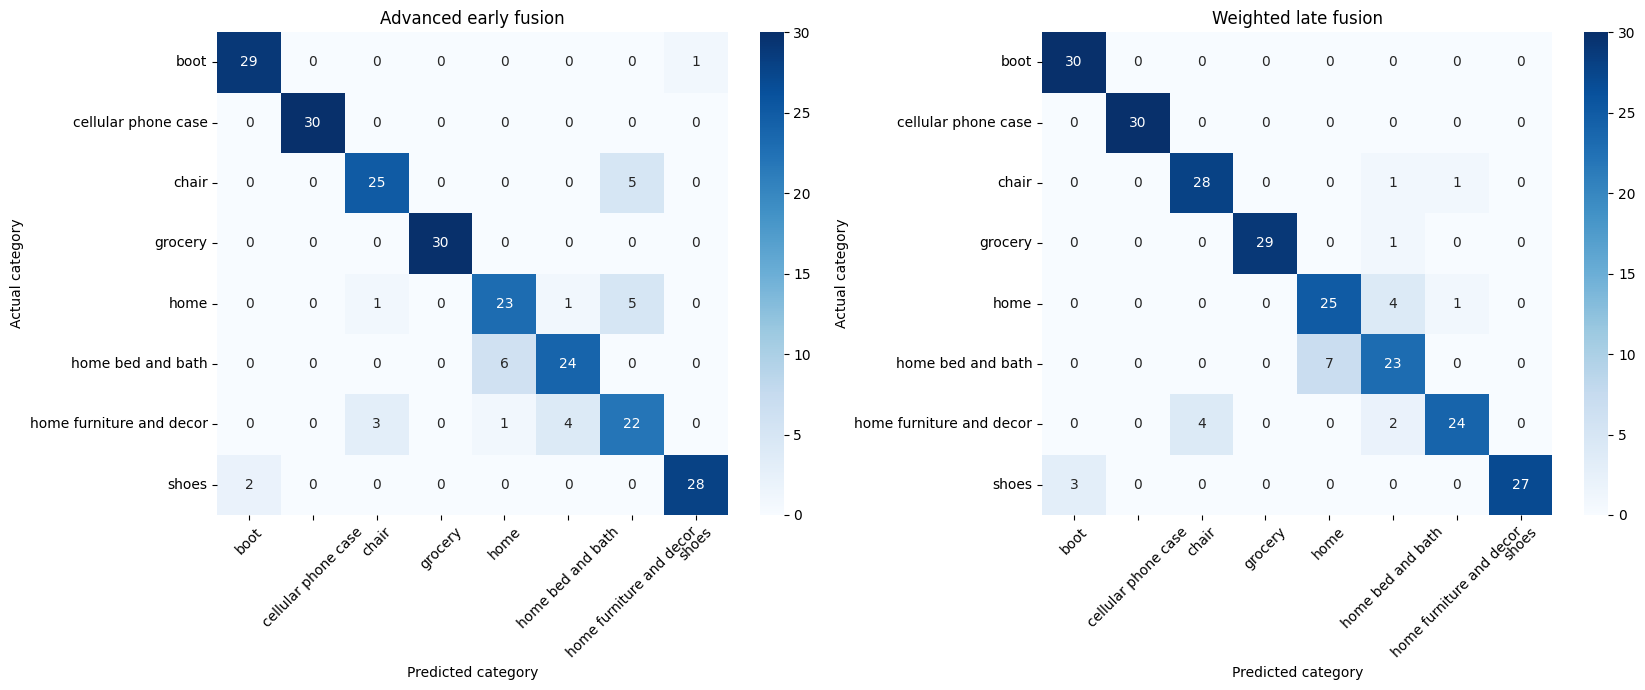


LATE FUSION CLASSIFICATION REPORT
--------------------------------
                          precision    recall  f1-score   support

                    boot       0.91      1.00      0.95        30
     cellular phone case       1.00      1.00      1.00        30
                   chair       0.88      0.93      0.90        30
                 grocery       1.00      0.97      0.98        30
                    home       0.78      0.83      0.81        30
       home bed and bath       0.74      0.77      0.75        30
home furniture and decor       0.92      0.80      0.86        30
                   shoes       1.00      0.90      0.95        30

                accuracy                           0.90       240
               macro avg       0.90      0.90      0.90       240
            weighted avg       0.90      0.90      0.90       240


STEP 24 COMPLETED


In [67]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)
from pathlib import Path

FIG_DIR = SAVE_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

for ax, (name, pred) in zip(
    axes,
    [
        ("Advanced early fusion", pred_early),
        ("Weighted late fusion", pred_late)
    ]
):
    cm = confusion_matrix(
        y_test,
        pred,
        labels=classes
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=classes,
        yticklabels=classes,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted category")
    ax.set_ylabel("Actual category")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "fusion_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nLATE FUSION CLASSIFICATION REPORT")
print("--------------------------------")
print(
    classification_report(
        y_test,
        pred_late,
        zero_division=0
    )
)

print("\nSTEP 24 COMPLETED")


In [68]:

import pandas as pd
import numpy as np

error_analysis = test_df.copy().reset_index(drop=True)

error_analysis["predicted_category"] = pred_late
error_analysis["actual_category"] = y_test.to_numpy()

error_analysis["correct"] = (
    error_analysis["predicted_category"]
    == error_analysis["actual_category"]
)

error_analysis["confidence"] = np.max(
    late_probs,
    axis=1
)

errors = error_analysis[
    ~error_analysis["correct"]
].copy()

print("Total test products:", len(error_analysis))
print("Correct predictions:", error_analysis["correct"].sum())
print("Incorrect predictions:", len(errors))

print("\nMISCLASSIFIED PRODUCTS")
print("----------------------")

print(
    errors[
        [
            "item_id",
            "title",
            "actual_category",
            "predicted_category",
            "confidence"
        ]
    ].to_string(
        index=False,
        max_colwidth=55
    )
)

errors.to_csv(
    SAVE_DIR / "late_fusion_errors.csv",
    index=False
)

print("\nSTEP 25 COMPLETED")


Total test products: 240
Correct predictions: 216
Incorrect predictions: 24

MISCLASSIFIED PRODUCTS
----------------------
   item_id                                                   title          actual_category       predicted_category  confidence
B076KSCP4P   AmazonBasics Mattress Encasement, 160 x 200 x 30.5 cm home furniture and decor        home bed and bath    0.463912
B07T7S3BTM South Pine - Cojín Redondo para Silla, diseño de Porche                     home        home bed and bath    0.231361
B07CN8KTL4           Amazon Brand - Solimo Iced Tea Bags, 24 Count                  grocery        home bed and bath    0.223361
B07H9VMXTW Umi. Essentials 100% cotton Yarn Dyed Duvet Cover Se...                     home        home bed and bath    0.482498
B01N9YMFLF 206 Collective Women's Ballard Chelsea Ankle Boot, B...                    shoes                     boot    0.457801
B08FHLWRYJ UMI. Seidenbettwäsche Set 2 teilig, Seide Bettbezug ...                     home        home

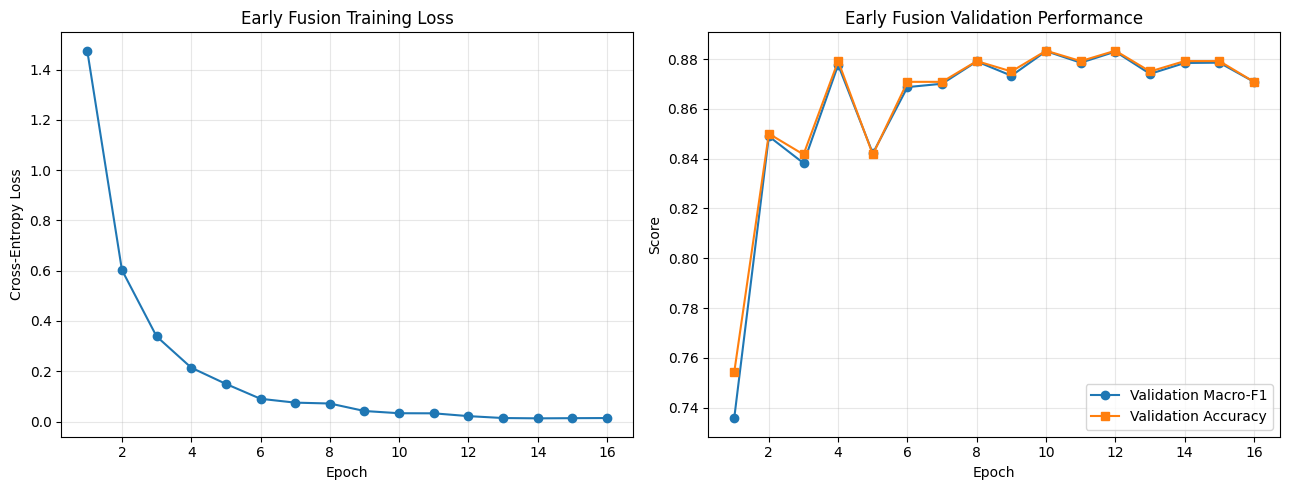

EARLY FUSION OVERFITTING ANALYSIS
---------------------------------
Training accuracy: 0.9982
Training Macro-F1: 0.9982
Validation accuracy: 0.8833
Validation Macro-F1: 0.8832
Test accuracy: 0.8792
Test Macro-F1: 0.8797
Train-validation accuracy gap: 0.1149

STEP 26 COMPLETED


In [69]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import torch
from sklearn.metrics import accuracy_score, f1_score

history_df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o"
)
axes[0].set_title("Early Fusion Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].grid(alpha=0.3)

axes[1].plot(
    history_df["epoch"],
    history_df["val_macro_f1"],
    marker="o",
    label="Validation Macro-F1"
)
axes[1].plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    marker="s",
    label="Validation Accuracy"
)
axes[1].set_title("Early Fusion Validation Performance")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "early_fusion_learning_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

early_fusion_model.eval()

train_predictions = []
train_targets = []

with torch.inference_mode():
    for image, text, labels in DataLoader(
        train_dataset,
        batch_size=64,
        shuffle=False
    ):
        outputs = early_fusion_model(
            image.to(device),
            text.to(device)
        )

        train_predictions.extend(
            outputs.argmax(1).cpu().numpy()
        )
        train_targets.extend(labels.numpy())

train_acc = accuracy_score(
    train_targets,
    train_predictions
)

train_f1 = f1_score(
    train_targets,
    train_predictions,
    average="macro"
)

print("EARLY FUSION OVERFITTING ANALYSIS")
print("---------------------------------")
print("Training accuracy:", round(train_acc, 4))
print("Training Macro-F1:", round(train_f1, 4))
print("Validation accuracy:", 0.8833)
print("Validation Macro-F1:", round(best_f1, 4))
print("Test accuracy:", 0.8792)
print("Test Macro-F1:", 0.8797)

print(
    "Train-validation accuracy gap:",
    round(train_acc - 0.8833, 4)
)

print("\nSTEP 26 COMPLETED")


In [70]:

import time
import numpy as np
import pandas as pd
import torch

def measure_time(fn, repeats=20):
    # Warm-up
    for _ in range(3):
        fn()

    times = []
    for _ in range(repeats):
        if device.type == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()
        fn()

        if device.type == "cuda":
            torch.cuda.synchronize()

        times.append(time.perf_counter() - start)

    return np.median(times) * 1000

def early_predict():
    with torch.inference_mode():
        early_fusion_model(
            image_tensor,
            text_tensor
        )

def late_predict():
    tp = text_model.predict_proba(X_test_tfidf)
    ip = image_model.predict_proba(X_test_img)
    return (
        0.7 * tp + 0.3 * ip
    ).argmax(axis=1)

early_ms = measure_time(early_predict)
late_ms = measure_time(late_predict)

parameter_count = sum(
    p.numel()
    for p in early_fusion_model.parameters()
)

efficiency_results = pd.DataFrame([
    {
        "Model": "Advanced early fusion",
        "Batch size": len(test_df),
        "Median classifier time (ms)": early_ms,
        "Trainable classifier parameters": parameter_count
    },
    {
        "Model": "Weighted late fusion",
        "Batch size": len(test_df),
        "Median classifier time (ms)": late_ms,
        "Trainable classifier parameters": "N/A - sklearn classifiers"
    }
])

print(efficiency_results.to_string(index=False))

efficiency_results.to_csv(
    SAVE_DIR / "efficiency_results.csv",
    index=False
)

print("\nSTEP 27 COMPLETED")


                Model  Batch size  Median classifier time (ms) Trainable classifier parameters
Advanced early fusion         240                     0.515182                          394632
 Weighted late fusion         240                     3.994744       N/A - sklearn classifiers

STEP 27 COMPLETED


In [71]:

from pathlib import Path
import shutil

SAVE_DIR = Path("/content/ABO_Assignment_2_2")

baseline_file = Path("/content/baseline_results.csv")

if baseline_file.exists():
    shutil.copy2(
        baseline_file,
        SAVE_DIR / "baseline_results.csv"
    )

archive_path = shutil.make_archive(
    "/content/ABO_Assignment_2_2_Results",
    "zip",
    root_dir="/content",
    base_dir="ABO_Assignment_2_2"
)

print("Results archive:", archive_path)

print("\nSaved evidence:")
for path in sorted(SAVE_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(SAVE_DIR))

print("\nSTEP 28 COMPLETED")


Results archive: /content/ABO_Assignment_2_2_Results.zip

Saved evidence:
abo_images.zip
baseline_results.csv
early_fusion_history.csv
early_fusion_model.pt
efficiency_results.csv
figures/early_fusion_learning_curves.png
figures/fusion_confusion_matrices.png
late_fusion_errors.csv
late_fusion_weight_search.csv
model_comparison_test.csv
model_comparison_validation.csv
test.csv
train.csv
val.csv

STEP 28 COMPLETED


In [72]:

import pandas as pd

splits = {
    "train": train_df,
    "validation": val_df,
    "test": test_df
}

for field in ["item_id", "main_image_url"]:
    print(f"\nChecking {field} overlap:")

    for a, b in [
        ("train", "validation"),
        ("train", "test"),
        ("validation", "test")
    ]:
        left = set(splits[a][field].dropna())
        right = set(splits[b][field].dropna())

        overlap = left.intersection(right)

        print(f"{a} vs {b}: {len(overlap)}")

print("\nRepeated normalised titles:")

normalised = {
    name: set(
        frame["title"]
        .fillna("")
        .astype(str)
        .str.lower()
        .str.strip()
    )
    for name, frame in splits.items()
}

for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]:
    print(
        f"{a} vs {b}:",
        len(normalised[a] & normalised[b])
    )

print("\nSTEP 29 COMPLETED")



Checking item_id overlap:
train vs validation: 0
train vs test: 0
validation vs test: 0

Checking main_image_url overlap:
train vs validation: 18
train vs test: 12
validation vs test: 8

Repeated normalised titles:
train vs validation: 5
train vs test: 2
validation vs test: 2

STEP 29 COMPLETED


In [73]:

import pandas as pd
from collections import defaultdict

data = balanced_df.copy().reset_index(drop=True)

data["normalised_title"] = (
    data["title"]
    .fillna("")
    .astype(str)
    .str.lower()
    .str.strip()
)

parent = list(range(len(data)))

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

for column in ["main_image_url", "normalised_title"]:
    first_seen = {}

    for idx, value in enumerate(data[column]):
        if pd.isna(value) or not str(value).strip():
            continue

        if value in first_seen:
            union(idx, first_seen[value])
        else:
            first_seen[value] = idx

data["leakage_group"] = [
    find(i) for i in range(len(data))
]

group_sizes = data["leakage_group"].value_counts()

print("Total products:", len(data))
print("Unique leakage groups:", len(group_sizes))
print("Groups with multiple products:", (group_sizes > 1).sum())
print("Largest group size:", group_sizes.max())

mixed_groups = (
    data.groupby("leakage_group")["product_type_readable"]
    .nunique()
)

print(
    "Groups containing multiple categories:",
    (mixed_groups > 1).sum()
)

print("\nSTEP 30 COMPLETED")


Total products: 1600
Unique leakage groups: 1480
Groups with multiple products: 76
Largest group size: 12
Groups containing multiple categories: 2

STEP 30 COMPLETED


In [74]:


group_label_counts = (
    data.groupby("leakage_group")["product_type_readable"]
    .nunique()
)

conflicting_groups = group_label_counts[
    group_label_counts > 1
].index

print("CONFLICTING GROUP ANALYSIS")
print("--------------------------")

for group_id in conflicting_groups:
    group_data = data[
        data["leakage_group"] == group_id
    ]

    print(f"\nGroup ID: {group_id}")
    print("Products:", len(group_data))

    print(
        group_data[
            [
                "item_id",
                "title",
                "product_type_readable",
                "main_image_url"
            ]
        ].to_string(
            index=False,
            max_colwidth=70
        )
    )

print("\nSTEP 31 COMPLETED")


CONFLICTING GROUP ANALYSIS
--------------------------

Group ID: 1252
Products: 2
   item_id                          title    product_type_readable                                                         main_image_url
B07CSYLKTQ Rivet Aged Black Swatch, Rivet                    chair https://amazon-berkeley-objects.s3.amazonaws.com/images/small/70/70...
B07CSX7N4X Rivet Aged Black Swatch, Rivet home furniture and decor https://amazon-berkeley-objects.s3.amazonaws.com/images/small/45/45...

Group ID: 1352
Products: 6
   item_id                                                                  title    product_type_readable                                                         main_image_url
B073G6DCJL Urban Living Skyline Lane Collection Lane Collection Living Room Ch...                    chair https://amazon-berkeley-objects.s3.amazonaws.com/images/small/87/87...
B073G8VWHF Urban Living Skyline Lane Collection Lane Collection Loveseat Loves...                    chair https://amazo

In [75]:

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42

grouped_df = data.copy().reset_index(drop=True)

X = grouped_df
y = grouped_df["product_type_readable"]
groups = grouped_df["leakage_group"]

sgkf = StratifiedGroupKFold(
    n_splits=10,
    shuffle=True,
    random_state=SEED
)

candidate_splits = []

for train_idx, holdout_idx in sgkf.split(X, y, groups):
    holdout_fraction = len(holdout_idx) / len(X)

    candidate_splits.append(
        (
            abs(holdout_fraction - 0.30),
            train_idx,
            holdout_idx
        )
    )

_, train_idx, holdout_idx = min(
    candidate_splits,
    key=lambda x: x[0]
)

new_train_df = grouped_df.iloc[
    train_idx
].copy()

holdout_df = grouped_df.iloc[
    holdout_idx
].copy()

sgkf2 = StratifiedGroupKFold(
    n_splits=2,
    shuffle=True,
    random_state=SEED
)

val_idx, test_idx = next(
    sgkf2.split(
        holdout_df,
        holdout_df["product_type_readable"],
        holdout_df["leakage_group"]
    )
)

new_val_df = holdout_df.iloc[val_idx].copy()
new_test_df = holdout_df.iloc[test_idx].copy()

for a, b in [
    (new_train_df, new_val_df),
    (new_train_df, new_test_df),
    (new_val_df, new_test_df)
]:
    assert set(a["leakage_group"]).isdisjoint(
        set(b["leakage_group"])
    )

print("NEW DATASET SPLITS")
print("------------------")
print("Training:", len(new_train_df))
print("Validation:", len(new_val_df))
print("Testing:", len(new_test_df))

print("\nCategory distribution:")
print(pd.DataFrame({
    "Train": new_train_df["product_type_readable"].value_counts(),
    "Val": new_val_df["product_type_readable"].value_counts(),
    "Test": new_test_df["product_type_readable"].value_counts()
}).fillna(0).astype(int))

print("\nNo leakage groups overlap.")
print("STEP 32 COMPLETED")


NEW DATASET SPLITS
------------------
Training: 1423
Validation: 77
Testing: 100

Category distribution:
                          Train  Val  Test
product_type_readable                     
boot                        178   11    11
cellular phone case         180    9    11
chair                       180   10    10
grocery                     180    9    11
home                        169   10    21
home bed and bath           182   10     8
home furniture and decor    181   10     9
shoes                       173    8    19

No leakage groups overlap.
STEP 32 COMPLETED


In [76]:

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

SEED = 42

grouped_df = data.copy().reset_index(drop=True)

def split_score(frame, target_fraction):
    counts = frame["product_type_readable"].value_counts()
    target_per_class = 200 * target_fraction

    size_penalty = abs(
        len(frame) - 1600 * target_fraction
    )

    balance_penalty = sum(
        abs(counts.get(c, 0) - target_per_class)
        for c in candidate_categories
    )

    return size_penalty + balance_penalty

best = None

for seed in range(100):
    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.30,
        random_state=seed
    )

    train_idx, holdout_idx = next(
        splitter.split(
            grouped_df,
            groups=grouped_df["leakage_group"]
        )
    )

    train_candidate = grouped_df.iloc[train_idx]
    holdout_candidate = grouped_df.iloc[holdout_idx]

    score = (
        split_score(train_candidate, 0.70)
        + split_score(holdout_candidate, 0.30)
    )

    if best is None or score < best[0]:
        best = (
            score,
            train_candidate.copy(),
            holdout_candidate.copy()
        )

new_train_df = best[1]
holdout_df = best[2]

best_holdout = None

for seed in range(100):
    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.50,
        random_state=seed
    )

    val_idx, test_idx = next(
        splitter.split(
            holdout_df,
            groups=holdout_df["leakage_group"]
        )
    )

    val_candidate = holdout_df.iloc[val_idx]
    test_candidate = holdout_df.iloc[test_idx]

    score = (
        split_score(val_candidate, 0.15)
        + split_score(test_candidate, 0.15)
    )

    if best_holdout is None or score < best_holdout[0]:
        best_holdout = (
            score,
            val_candidate.copy(),
            test_candidate.copy()
        )

new_val_df = best_holdout[1]
new_test_df = best_holdout[2]

for a, b in [
    (new_train_df, new_val_df),
    (new_train_df, new_test_df),
    (new_val_df, new_test_df)
]:
    assert set(a["leakage_group"]).isdisjoint(
        set(b["leakage_group"])
    )

print("CORRECTED DATASET SPLITS")
print("------------------------")
print("Training:", len(new_train_df))
print("Validation:", len(new_val_df))
print("Testing:", len(new_test_df))

print("\nClass distribution:")
print(pd.DataFrame({
    "Train": new_train_df["product_type_readable"].value_counts(),
    "Val": new_val_df["product_type_readable"].value_counts(),
    "Test": new_test_df["product_type_readable"].value_counts()
}).fillna(0).astype(int))

print("\nNo leakage groups overlap.")
print("STEP 33 COMPLETED")


CORRECTED DATASET SPLITS
------------------------
Training: 1120
Validation: 240
Testing: 240

Class distribution:
                          Train  Val  Test
product_type_readable                     
boot                        140   29    31
cellular phone case         141   31    28
chair                       141   29    30
grocery                     135   36    29
home                        140   30    30
home bed and bath           139   31    30
home furniture and decor    137   30    33
shoes                       147   24    29

No leakage groups overlap.
STEP 33 COMPLETED


In [77]:

import pandas as pd

train_df = new_train_df.copy().reset_index(drop=True)
val_df = new_val_df.copy().reset_index(drop=True)
test_df = new_test_df.copy().reset_index(drop=True)

splits = {
    "train": train_df,
    "validation": val_df,
    "test": test_df
}

for column in ["item_id", "main_image_url", "normalised_title"]:
    for a, b in [
        ("train", "validation"),
        ("train", "test"),
        ("validation", "test")
    ]:
        overlap = (
            set(splits[a][column].dropna())
            & set(splits[b][column].dropna())
        )

        assert len(overlap) == 0, (
            f"Leakage detected in {column}: {a} vs {b}"
        )

from pathlib import Path

image_dir = Path("/content/abo_images")

for frame in [train_df, val_df, test_df]:
    missing = [
        item_id
        for item_id in frame["item_id"]
        if not (image_dir / f"{item_id}.jpg").exists()
    ]

    assert len(missing) == 0, (
        f"{len(missing)} images missing"
    )

# Save corrected splits separately
CORRECTED_DIR = Path(
    "/content/ABO_Assignment_2_2_Corrected"
)
CORRECTED_DIR.mkdir(parents=True, exist_ok=True)

train_df.to_csv(CORRECTED_DIR / "train.csv", index=False)
val_df.to_csv(CORRECTED_DIR / "val.csv", index=False)
test_df.to_csv(CORRECTED_DIR / "test.csv", index=False)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nNo shared IDs, image URLs or titles.")
print("All selected images exist.")
print("Corrected splits saved.")
print("STEP 34 COMPLETED")


Training: 1120
Validation: 240
Testing: 240

No shared IDs, image URLs or titles.
All selected images exist.
Corrected splits saved.
STEP 34 COMPLETED


In [78]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

X_train = train_df["title"].fillna("").astype(str)
X_val = val_df["title"].fillna("").astype(str)

y_train = train_df["product_type_readable"]
y_val = val_df["product_type_readable"]

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)


text_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

text_model.fit(X_train_tfidf, y_train)

train_pred = text_model.predict(X_train_tfidf)
val_pred = text_model.predict(X_val_tfidf)

train_acc = accuracy_score(y_train, train_pred)
val_acc = accuracy_score(y_val, val_pred)
val_f1 = f1_score(y_val, val_pred, average="macro")

print("CORRECTED TEXT-ONLY BASELINE")
print("----------------------------")
print("Training accuracy:", round(train_acc, 4))
print("Validation accuracy:", round(val_acc, 4))
print("Validation Macro-F1:", round(val_f1, 4))

print("\nTraining-validation gap:",
      round(train_acc - val_acc, 4))

print("\nTF-IDF feature count:",
      X_train_tfidf.shape[1])

print("\nSTEP 35 COMPLETED")


CORRECTED TEXT-ONLY BASELINE
----------------------------
Training accuracy: 0.9545
Validation accuracy: 0.8333
Validation Macro-F1: 0.8326

Training-validation gap: 0.1211

TF-IDF feature count: 2381

STEP 35 COMPLETED


In [79]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

print("Extracting corrected training image features...")
X_train_img = extract_image_features(train_df)

print("Extracting corrected validation image features...")
X_val_img = extract_image_features(val_df)

image_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

image_model.fit(
    X_train_img,
    y_train
)

train_img_pred = image_model.predict(X_train_img)
val_img_pred = image_model.predict(X_val_img)

train_img_acc = accuracy_score(
    y_train,
    train_img_pred
)

val_img_acc = accuracy_score(
    y_val,
    val_img_pred
)

val_img_f1 = f1_score(
    y_val,
    val_img_pred,
    average="macro"
)

print("\nCORRECTED IMAGE-ONLY BASELINE")
print("-----------------------------")
print("Training accuracy:", round(train_img_acc, 4))
print("Validation accuracy:", round(val_img_acc, 4))
print("Validation Macro-F1:", round(val_img_f1, 4))

print("\nTraining-validation gap:",
      round(train_img_acc - val_img_acc, 4))

print("\nSTEP 36 COMPLETED")


Extracting corrected training image features...


  0%|          | 0/1120 [00:00<?, ?it/s]

Extracting corrected validation image features...


  0%|          | 0/240 [00:00<?, ?it/s]


CORRECTED IMAGE-ONLY BASELINE
-----------------------------
Training accuracy: 0.9982
Validation accuracy: 0.8583
Validation Macro-F1: 0.8516

Training-validation gap: 0.1399

STEP 36 COMPLETED


Corrected dataset verified.
Text-only model completed.


  0%|          | 0/1120 [00:00<?, ?it/s]

  0%|          | 0/240 [00:00<?, ?it/s]

  0%|          | 0/240 [00:00<?, ?it/s]

Image-only model completed.
Simple multimodal model completed.
Late fusion completed.
Best text weight: 0.65
Best image weight: 0.35


  0%|          | 0/35 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

Epoch 01 | Validation Macro-F1: 0.7146
Epoch 02 | Validation Macro-F1: 0.8081
Epoch 03 | Validation Macro-F1: 0.8481
Epoch 04 | Validation Macro-F1: 0.8759
Epoch 05 | Validation Macro-F1: 0.8883
Epoch 06 | Validation Macro-F1: 0.8883
Epoch 07 | Validation Macro-F1: 0.8849
Epoch 08 | Validation Macro-F1: 0.8931
Epoch 09 | Validation Macro-F1: 0.9022
Epoch 10 | Validation Macro-F1: 0.9055
Epoch 11 | Validation Macro-F1: 0.9009
Epoch 12 | Validation Macro-F1: 0.8924
Epoch 13 | Validation Macro-F1: 0.8928
Epoch 14 | Validation Macro-F1: 0.8976
Epoch 15 | Validation Macro-F1: 0.8921
Epoch 16 | Validation Macro-F1: 0.8753
Early stopping triggered.
Early fusion completed.

CORRECTED FINAL TEST RESULTS
            Model  Accuracy  Macro Precision  Macro Recall  Macro-F1
        Text-only    0.8417           0.8481        0.8457    0.8450
       Image-only    0.7833           0.7957        0.7867    0.7896
Simple multimodal    0.7875           0.7970        0.7900    0.7927
     Early fusion   

In [ ]:

import copy
import random
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

OUT = Path("/content/ABO_Final_Corrected")
OUT.mkdir(parents=True, exist_ok=True)

train_df = new_train_df.copy().reset_index(drop=True)
val_df = new_val_df.copy().reset_index(drop=True)
test_df = new_test_df.copy().reset_index(drop=True)

for a, b in [
    (train_df, val_df),
    (train_df, test_df),
    (val_df, test_df)
]:
    assert set(a["leakage_group"]).isdisjoint(
        set(b["leakage_group"])
    )

y_train = train_df["product_type_readable"]
y_val = val_df["product_type_readable"]
y_test = test_df["product_type_readable"]

classes = sorted(y_train.unique())
class_to_idx = {c: i for i, c in enumerate(classes)}

def encode_labels(y):
    return torch.tensor(
        [class_to_idx[v] for v in y],
        dtype=torch.long
    )

print("Corrected dataset verified.")

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2
)

Xt = tfidf.fit_transform(
    train_df["title"].fillna("").astype(str)
)
Xv = tfidf.transform(
    val_df["title"].fillna("").astype(str)
)
Xe = tfidf.transform(
    test_df["title"].fillna("").astype(str)
)

text_model = LogisticRegression(
    max_iter=1000,
    random_state=SEED
)
text_model.fit(Xt, y_train)

print("Text-only model completed.")

Xi = extract_image_features(train_df)
Xiv = extract_image_features(val_df)
Xie = extract_image_features(test_df)

image_model = LogisticRegression(
    max_iter=2000,
    random_state=SEED
)
image_model.fit(Xi, y_train)

print("Image-only model completed.")

simple_scaler = StandardScaler()

Si = simple_scaler.fit_transform(Xi)
Siv = simple_scaler.transform(Xiv)
Sie = simple_scaler.transform(Xie)

combined_model = LogisticRegression(
    max_iter=2000,
    random_state=SEED
)

combined_model.fit(
    hstack([Xt, csr_matrix(Si)]).tocsr(),
    y_train
)

print("Simple multimodal model completed.")

assert np.array_equal(
    text_model.classes_,
    image_model.classes_
)

tpv = text_model.predict_proba(Xv)
ipv = image_model.predict_proba(Xiv)

weight_results = []

for w in np.linspace(0, 1, 21):
    probs = w * tpv + (1 - w) * ipv
    pred = text_model.classes_[
        probs.argmax(axis=1)
    ]

    weight_results.append({
        "text_weight": float(w),
        "image_weight": float(1 - w),
        "val_macro_f1": f1_score(
            y_val, pred, average="macro"
        ),
        "val_accuracy": accuracy_score(
            y_val, pred
        )
    })

weight_df = pd.DataFrame(weight_results)

weight_df.to_csv(
    OUT / "late_weight_search.csv",
    index=False
)

best_row = weight_df.sort_values(
    ["val_macro_f1", "val_accuracy", "text_weight"],
    ascending=[False, False, True]
).iloc[0]

best_w = float(best_row["text_weight"])

print("Late fusion completed.")
print("Best text weight:", round(best_w, 2))
print("Best image weight:", round(1 - best_w, 2))

Bt = extract_text_embeddings(train_df)
Bv = extract_text_embeddings(val_df)
Be = extract_text_embeddings(test_df)

img_scaler = StandardScaler()
bert_scaler = StandardScaler()

Ei = img_scaler.fit_transform(Xi)
Eiv = img_scaler.transform(Xiv)
Eie = img_scaler.transform(Xie)

Et = bert_scaler.fit_transform(Bt)
Etv = bert_scaler.transform(Bv)
Ete = bert_scaler.transform(Be)

def make_loader(a, b, y, shuffle=False):
    dataset = TensorDataset(
        torch.tensor(a, dtype=torch.float32),
        torch.tensor(b, dtype=torch.float32),
        encode_labels(y)
    )

    return DataLoader(
        dataset,
        batch_size=64,
        shuffle=shuffle
    )

train_loader = make_loader(
    Ei, Et, y_train, True
)
val_loader = make_loader(
    Eiv, Etv, y_val
)

early_fusion_model = EarlyFusionNet(
    len(classes)
).to(device)

optimizer = torch.optim.AdamW(
    early_fusion_model.parameters(),
    lr=0.0005,
    weight_decay=0.01
)

criterion = torch.nn.CrossEntropyLoss()

best_score = -1
best_state = None
wait = 0
history = []

for epoch in range(1, 31):
    early_fusion_model.train()
    total_loss = 0

    for image, text, labels in train_loader:
        image = image.to(device)
        text = text.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = early_fusion_model(
            image, text
        )

        loss = criterion(
            outputs, labels
        )

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(labels)

    early_fusion_model.eval()
    predictions_val = []

    with torch.inference_mode():
        for image, text, labels in val_loader:
            outputs = early_fusion_model(
                image.to(device),
                text.to(device)
            )

            predictions_val.extend(
                outputs.argmax(1).cpu().numpy()
            )

    score = f1_score(
        encode_labels(y_val).numpy(),
        predictions_val,
        average="macro"
    )

    history.append({
        "epoch": epoch,
        "train_loss": total_loss / len(y_train),
        "val_macro_f1": score
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Validation Macro-F1: {score:.4f}"
    )

    if score > best_score + 0.0001:
        best_score = score
        best_state = copy.deepcopy(
            early_fusion_model.state_dict()
        )
        wait = 0
    else:
        wait += 1

    if wait >= 6:
        print("Early stopping triggered.")
        break

early_fusion_model.load_state_dict(
    best_state
)
early_fusion_model.eval()

pd.DataFrame(history).to_csv(
    OUT / "early_fusion_history.csv",
    index=False
)

torch.save({
    "model_state_dict": best_state,
    "classes": classes,
    "image_scaler_mean": img_scaler.mean_,
    "image_scaler_scale": img_scaler.scale_,
    "text_scaler_mean": bert_scaler.mean_,
    "text_scaler_scale": bert_scaler.scale_,
    "seed": SEED
}, OUT / "early_fusion_model.pt")

print("Early fusion completed.")

with torch.inference_mode():
    early_outputs = early_fusion_model(
        torch.tensor(
            Eie,
            dtype=torch.float32,
            device=device
        ),
        torch.tensor(
            Ete,
            dtype=torch.float32,
            device=device
        )
    )

pred_early = np.array(classes)[
    early_outputs.argmax(1).cpu().numpy()
]

late_probs = (
    best_w * text_model.predict_proba(Xe)
    + (1 - best_w) * image_model.predict_proba(Xie)
)

pred_late = text_model.classes_[
    late_probs.argmax(axis=1)
]

predictions = {
    "Text-only": text_model.predict(Xe),
    "Image-only": image_model.predict(Xie),
    "Simple multimodal": combined_model.predict(
        hstack([
            Xe,
            csr_matrix(Sie)
        ]).tocsr()
    ),
    "Early fusion": pred_early,
    "Late fusion": pred_late
}

results = []

for name, pred in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_test, pred
        ),
        "Macro Precision": precision_score(
            y_test,
            pred,
            average="macro",
            zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test,
            pred,
            average="macro",
            zero_division=0
        ),
        "Macro-F1": f1_score(
            y_test,
            pred,
            average="macro",
            zero_division=0
        )
    })

final_results = pd.DataFrame(results)

final_results.to_csv(
    OUT / "corrected_test_results.csv",
    index=False
)

pd.DataFrame({
    "item_id": test_df["item_id"],
    "actual": y_test,
    **predictions
}).to_csv(
    OUT / "test_predictions.csv",
    index=False
)

for name, frame in [
    ("train", train_df),
    ("val", val_df),
    ("test", test_df)
]:
    frame.to_csv(
        OUT / f"{name}.csv",
        index=False
    )

print("\n================================")
print("CORRECTED FINAL TEST RESULTS")
print("================================")

print(
    final_results.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nBest late-fusion weights:")
print("Text:", round(best_w, 2))
print("Image:", round(1 - best_w, 2))

print(
    "\nBest early-fusion validation Macro-F1:",
    round(best_score, 4)
)

print("\nALL MODELS COMPLETED")


In [82]:

import shutil

shutil.make_archive(
    "/content/ABO_Final_Corrected",
    "zip",
    "/content",
    "ABO_Final_Corrected"
)

print("BACKUP COMPLETED")


BACKUP COMPLETED
